# TP 4a — Traiter une image avec NumPy (corrigé)
Aucune boucle : chaque opération porte sur le tableau entier.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cbook

## 1. Charger et inspecter

In [2]:
with cbook.get_sample_data("grace_hopper.jpg") as f:
    img = plt.imread(f)
print(img.shape, img.dtype, img.min(), img.max())
for i, canal in enumerate("RVB"):
    print(canal, img[..., i].min(), img[..., i].max())

(600, 512, 3) uint8 0 255
R 0 255
V 0 255
B 0 255


## 2. Niveaux de gris, par produit matriciel

In [3]:
gris = img @ np.array([0.299, 0.587, 0.114])   # (600, 512, 3) @ (3,) → (600, 512)
print(gris.shape, gris.dtype)

(600, 512) float64


## 3. Recadrer, retourner, réduire : des tranches

In [4]:
visage = img[60:330, 130:380]
miroir = img[:, ::-1]
petite = img[::2, ::2]
print(visage.shape, miroir.shape, petite.shape)

(270, 250, 3) (600, 512, 3) (300, 256, 3)


## 4. Négatif et seuillage

In [5]:
negatif = 255 - img
masque = gris > 128
print(f"{masque.mean():.3f} des pixels dépassent 128")

0.285 des pixels dépassent 128


## 5. La planche de cinq vignettes

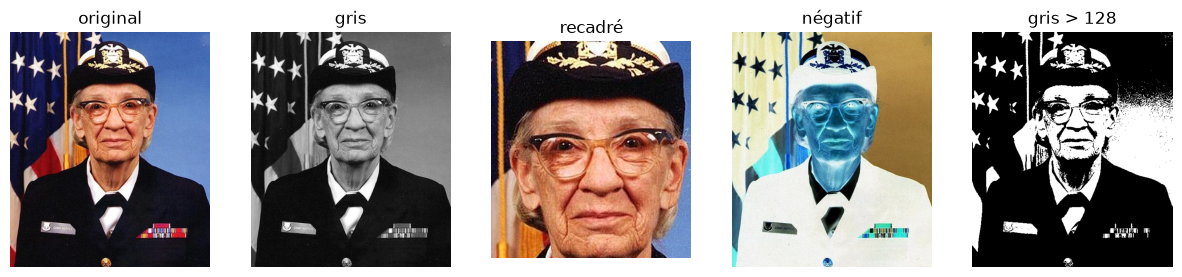

In [6]:
fig, axes = plt.subplots(1, 5, figsize=(15, 3.6))
vignettes = [(img, "original", None), (gris, "gris", "gray"), (visage, "recadré", None),
             (negatif, "négatif", None), (masque, "gris > 128", "gray")]
for ax, (im, titre, cmap) in zip(axes, vignettes):
    ax.imshow(im, cmap=cmap)
    ax.set_title(titre)
    ax.axis("off")
fig.savefig("planche.png", dpi=100, bbox_inches="tight")

## Bonus : histogramme, et éclaircir sans déborder

[206 214 206] [30 38 30] ← 206 + 80 = 30 : débordement silencieux
uint8 255


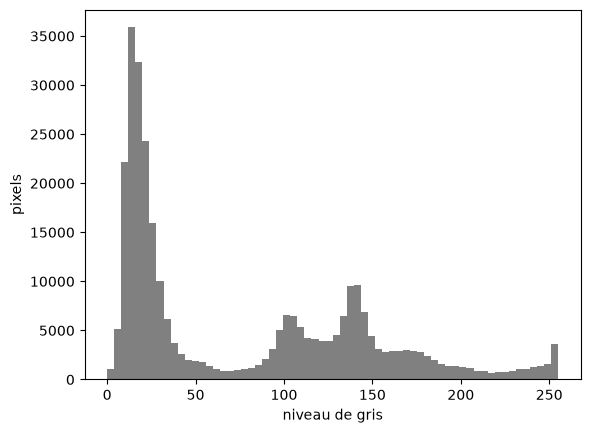

In [7]:
fig, ax = plt.subplots()
ax.hist(gris.ravel(), bins=64, color="gray")
ax.set_xlabel("niveau de gris")
ax.set_ylabel("pixels")

# Le piège : un uint8 + 80 reste un uint8, et « tourne » au-delà de 255
brillants = img[img > 200][:3]
print(brillants, brillants + 80, "← 206 + 80 = 30 : débordement silencieux")
clair = np.clip(img.astype(float) * 1.3, 0, 255).astype(np.uint8)
print(clair.dtype, clair.max())